In [ ]:
import sqlite3
import pandas as pd
import numpy as np
import networkx as nx

DB_PATH = "/home/hl/uu/informationsutvinning/project/cleaned_dataset/DMProjectDB_cleaned-002.db"
conn = sqlite3.connect(DB_PATH)

edges_df = pd.read_sql_query("SELECT FollowerID, FollowedID FROM followers", conn)

G = nx.from_pandas_edgelist(edges_df, source='FollowerID', target='FollowedID', create_using=nx.DiGraph())

pagerank_dict = nx.pagerank(G, alpha=0.85)
pagerank_df = pd.DataFrame(list(pagerank_dict.items()), columns=['AuthorID', 'PageRank'])

query = """
SELECT 
    e.EntryID,
    e.PostedBy AS AuthorID,
    COALESCE(l.LikeCount, 0) AS NumLikes,
    COALESCE(c.CommentCount, 0) AS NumComments,
    (COALESCE(l.LikeCount, 0) + COALESCE(c.CommentCount, 0)) AS TotalEngagement,
    COALESCE(f_in.FollowerCount, 0) AS Followers,
    COALESCE(f_out.FollowingCount, 0) AS Following
FROM entries e
-- Join aggregated likes per entry
LEFT JOIN (
    SELECT EntryID, COUNT(*) AS LikeCount 
    FROM likes 
    GROUP BY EntryID
) l ON e.EntryID = l.EntryID
-- Join aggregated comments per entry
LEFT JOIN (
    SELECT EntryID, COUNT(*) AS CommentCount 
    FROM comments 
    GROUP BY EntryID
) c ON e.EntryID = c.EntryID
-- Join author follower count (In-degree)
LEFT JOIN (
    SELECT FollowedID AS UserID, COUNT(*) AS FollowerCount 
    FROM followers 
    GROUP BY FollowedID
) f_in ON e.PostedBy = f_in.UserID
-- Join author following count (Out-degree)
LEFT JOIN (
    SELECT FollowerID AS UserID, COUNT(*) AS FollowingCount 
    FROM followers 
    GROUP BY FollowerID
) f_out ON e.PostedBy = f_out.UserID;
"""

df_raw = pd.read_sql_query(query, conn)
conn.close()

df_full = pd.merge(df_raw, pagerank_df, on='AuthorID', how='left')
df_full['PageRank'] = df_full['PageRank'].fillna(0)

print(f"Total entries loaded: {len(df_raw)}")

Total entries loaded: 11043310


In [ ]:
df = df_full[df_full['TotalEngagement'] > 0].copy()

df['FF_Ratio'] = df['Followers'] / (df['Following'] + 1)

print(f"Active entries with engagement > 0: {len(df)}")

Active entries with engagement > 0: 1170682


In [ ]:
df['Follower_Bin'] = pd.qcut(df['Followers'], q=3, labels=['Followers_Low', 'Followers_Med', 'Followers_High'], duplicates='drop')
df['Following_Bin'] = pd.qcut(df['Following'], q=3, labels=['Following_Low', 'Following_Med', 'Following_High'], duplicates='drop')
df['PageRank_Bin'] = pd.qcut(df['PageRank'], q=3, labels=['PageRank_Low', 'PageRank_Med', 'PageRank_High'], duplicates='drop')
df['Ratio_Bin'] = pd.qcut(df['FF_Ratio'], q=3, labels=['Ratio_Low', 'Ratio_Med', 'Ratio_High'], duplicates='drop')

df['Engagement_Bin'] = pd.cut(df['TotalEngagement'], bins=[0, 1, 5,float('inf')], labels=['Eng_Low', 'Eng_Med', 'Eng_High'], duplicates='drop')

print(df['Engagement_Bin'].value_counts())


Engagement_Bin
Eng_Low     903736
Eng_Med     157789
Eng_High    109157
Name: count, dtype: int64


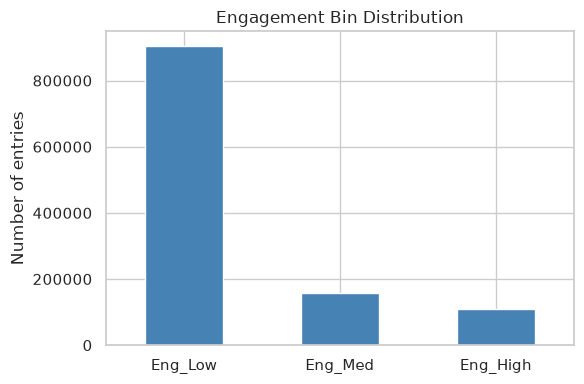

In [21]:
import matplotlib.pyplot as plt

counts = df['Engagement_Bin'].value_counts(sort=False)

ax = counts.plot(kind='bar', color='steelblue', figsize=(6, 4))
ax.set_title('Engagement Bin Distribution')
ax.set_xlabel('')
ax.set_ylabel('Number of entries')
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

features_to_mine = ['Follower_Bin', 'Following_Bin', 'PageRank_Bin', 'Ratio_Bin', 'Engagement_Bin']
transactions = pd.get_dummies(df[features_to_mine], prefix='', prefix_sep='')

frequent_itemsets = apriori(transactions, min_support=0.01, use_colnames=True)

rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

engagement_rules = rules[
    rules['consequents'].apply(lambda x: any('Eng' in item for item in x)) & rules['consequents'].apply(len)
].sort_values(by='lift', ascending=False)
engagement_rules = engagement_rules[
    engagement_rules['consequents'].apply(
        lambda items: len(items) == 1 and all(item.startswith('Eng_') for item in items)
    )
].copy()

print(f"Total number of engagement rules: {len(engagement_rules)}")


Total number of engagement rules: 160


In [78]:
# Display top 10 rules sorted by lift
engagement_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10)



,antecedents,consequents,support,confidence,lift
2408,"frozenset({PageRank_High, Ratio_Med, Followers_High, Following_High})",frozenset({Eng_High}),0.038442,0.278613,2.988058
1789,"frozenset({PageRank_High, Ratio_Med, Following_High})",frozenset({Eng_High}),0.039630,0.277528,2.976415
1528,"frozenset({PageRank_High, Ratio_Med, Followers_High})",frozenset({Eng_High}),0.040389,0.274959,2.948865
1451,"frozenset({Ratio_Med, Followers_High, Following_High})",frozenset({Eng_High}),0.038672,0.267973,2.873947
581,"frozenset({Ratio_Med, Following_High})",frozenset({Eng_High}),0.041165,0.264966,2.841698
1377,"frozenset({PageRank_High, Followers_High, Following_High})",frozenset({Eng_High}),0.062810,0.263327,2.824113
636,"frozenset({PageRank_High, Ratio_Med})",frozenset({Eng_High}),0.043663,0.262799,2.818458
551,"frozenset({PageRank_High, Following_High})",frozenset({Eng_High}),0.065268,0.259223,2.780101
388,"frozenset({Ratio_Med, Followers_High})",frozenset({Eng_High}),0.040995,0.259107,2.778856
331,"frozenset({Followers_High, Following_High})",frozenset({Eng_High}),0.064761,0.248238,2.662296


In [79]:
# Display top 10 rules sorted by support
engagement_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values(by='support', ascending=False).head(10)

,antecedents,consequents,support,confidence,lift
32,frozenset({Following_Low}),frozenset({Eng_Low}),0.341744,0.984294,1.275035
8,frozenset({Followers_Low}),frozenset({Eng_Low}),0.329975,0.975419,1.263538
56,frozenset({PageRank_Low}),frozenset({Eng_Low}),0.327094,0.980963,1.270721
74,frozenset({Ratio_High}),frozenset({Eng_Low}),0.302101,0.910602,1.179576
61,frozenset({PageRank_Med}),frozenset({Eng_Low}),0.281567,0.844957,1.094540
16,frozenset({Followers_Med}),frozenset({Eng_Low}),0.272697,0.826876,1.071119
138,"frozenset({PageRank_Low, Followers_Low})",frozenset({Eng_Low}),0.267887,0.980675,1.270347
42,frozenset({Following_Med}),frozenset({Eng_Low}),0.266822,0.834624,1.081156
445,"frozenset({Following_Low, Ratio_High})",frozenset({Eng_Low}),0.226557,0.981908,1.271944
98,"frozenset({Following_Low, Followers_Low})",frozenset({Eng_Low}),0.212900,0.988173,1.280060


In [80]:
# Display top 10 rules sorted by confidence
engagement_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values(by='confidence', ascending=False).head(10)

,antecedents,consequents,support,confidence,lift
1830,"frozenset({Ratio_Med, Followers_Low, Following_Low, PageRank_Low})",frozenset({Eng_Low}),0.054820,0.994530,1.288294
1587,"frozenset({Ratio_Med, Following_Low, PageRank_Low})",frozenset({Eng_Low}),0.054820,0.994530,1.288294
442,"frozenset({Ratio_Med, Following_Low})",frozenset({Eng_Low}),0.058042,0.993363,1.286783
731,"frozenset({Ratio_Med, Following_Low, Followers_Low})",frozenset({Eng_Low}),0.058042,0.993363,1.286783
853,"frozenset({Ratio_Med, Followers_Low, PageRank_Low})",frozenset({Eng_Low}),0.065524,0.990535,1.283119
592,"frozenset({Ratio_Med, PageRank_Low})",frozenset({Eng_Low}),0.075820,0.989962,1.282378
690,"frozenset({PageRank_Low, Following_Low, Followers_Low})",frozenset({Eng_Low}),0.181047,0.988900,1.281002
98,"frozenset({Following_Low, Followers_Low})",frozenset({Eng_Low}),0.212900,0.988173,1.280060
418,"frozenset({PageRank_Low, Following_Low})",frozenset({Eng_Low}),0.205331,0.988165,1.280049
1888,"frozenset({Followers_Low, Following_Low, PageRank_Med, Ratio_High})",frozenset({Eng_Low}),0.027055,0.987652,1.279385


In [ ]:
high_engagement_rules = rules[
    rules['consequents'].apply(
        lambda items: items == {'Eng_High'}
    )
    & rules['antecedents'].apply(
        lambda items: all(not item.startswith('Eng_') for item in items)
    )
].copy()

interesting = high_engagement_rules[
    (high_engagement_rules['support'] >= 0.01) &
    (high_engagement_rules['confidence'] >= 0.20) &
    (high_engagement_rules['lift'] > 1.0)
].sort_values(['lift', 'confidence', 'support'], ascending=False)

pd.set_option('display.max_colwidth', None)
interesting['antecedents'] = interesting['antecedents'].apply(
    lambda items: '{' + ', '.join(sorted(items)) + '}'
)
interesting['consequents'] = interesting['consequents'].apply(
    lambda items: '{' + ', '.join(sorted(items)) + '}'
)
print(
    interesting[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
    .head(20)
    .to_string(index=False, line_width=10**9)
)
interesting[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(20)

                                               antecedents consequents  support  confidence     lift
{Followers_High, Following_High, PageRank_High, Ratio_Med}  {Eng_High} 0.038442    0.278613 2.988058
                {Following_High, PageRank_High, Ratio_Med}  {Eng_High} 0.039630    0.277528 2.976415
                {Followers_High, PageRank_High, Ratio_Med}  {Eng_High} 0.040389    0.274959 2.948865
               {Followers_High, Following_High, Ratio_Med}  {Eng_High} 0.038672    0.267973 2.873947
                               {Following_High, Ratio_Med}  {Eng_High} 0.041165    0.264966 2.841698
           {Followers_High, Following_High, PageRank_High}  {Eng_High} 0.062810    0.263327 2.824113
                                {PageRank_High, Ratio_Med}  {Eng_High} 0.043663    0.262799 2.818458
                           {Following_High, PageRank_High}  {Eng_High} 0.065268    0.259223 2.780101
                               {Followers_High, Ratio_Med}  {Eng_High} 0.040995    0.259107

,antecedents,consequents,support,confidence,lift
2408,"{Followers_High, Following_High, PageRank_High, Ratio_Med}",{Eng_High},0.038442,0.278613,2.988058
1789,"{Following_High, PageRank_High, Ratio_Med}",{Eng_High},0.039630,0.277528,2.976415
1528,"{Followers_High, PageRank_High, Ratio_Med}",{Eng_High},0.040389,0.274959,2.948865
1451,"{Followers_High, Following_High, Ratio_Med}",{Eng_High},0.038672,0.267973,2.873947
581,"{Following_High, Ratio_Med}",{Eng_High},0.041165,0.264966,2.841698
1377,"{Followers_High, Following_High, PageRank_High}",{Eng_High},0.062810,0.263327,2.824113
636,"{PageRank_High, Ratio_Med}",{Eng_High},0.043663,0.262799,2.818458
551,"{Following_High, PageRank_High}",{Eng_High},0.065268,0.259223,2.780101
388,"{Followers_High, Ratio_Med}",{Eng_High},0.040995,0.259107,2.778856
331,"{Followers_High, Following_High}",{Eng_High},0.064761,0.248238,2.662296


/tmp/ipykernel_4127/3904839441.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Engagement_Bin', y='Followers', ax=axes[1], palette='Blues')
/home/hl/uu/informationsutvinning/project/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/hl/uu/informationsutvinning/project/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/hl/uu/informationsutvinning/project/.venv/lib/python3.14/site-packages/seaborn/categorical.py:

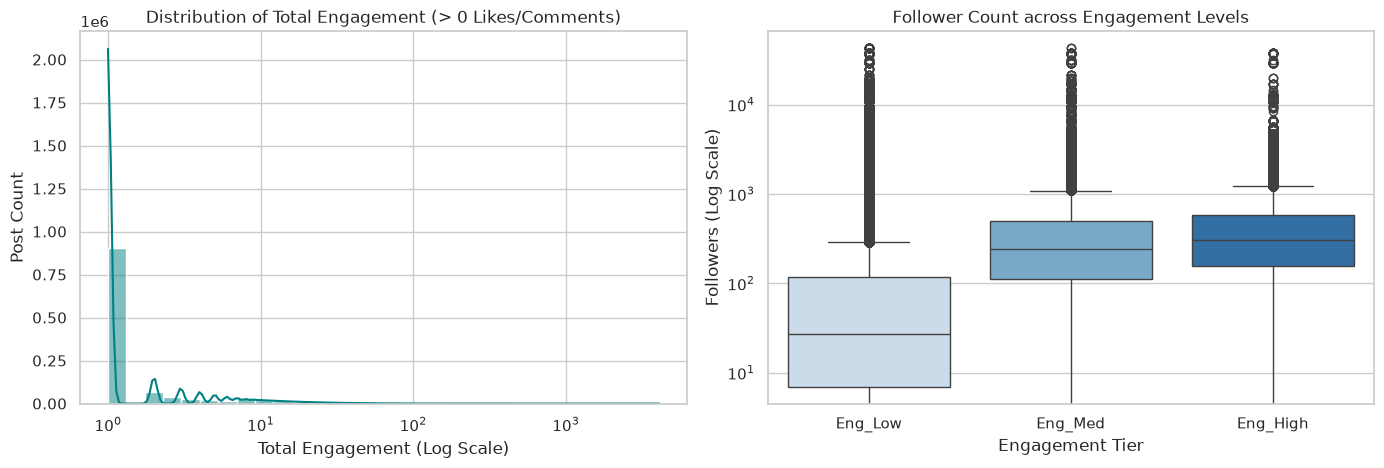

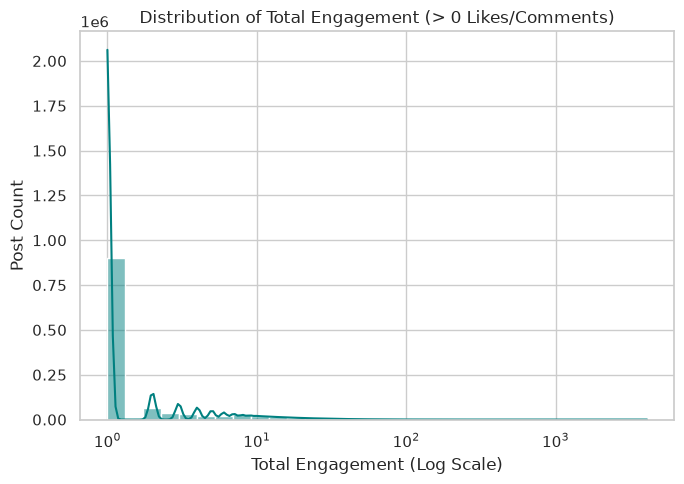

/tmp/ipykernel_4127/3904839441.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Engagement_Bin", y="Followers", palette="Blues")
/home/hl/uu/informationsutvinning/project/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/hl/uu/informationsutvinning/project/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/hl/uu/informationsutvinning/project/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: Matplot

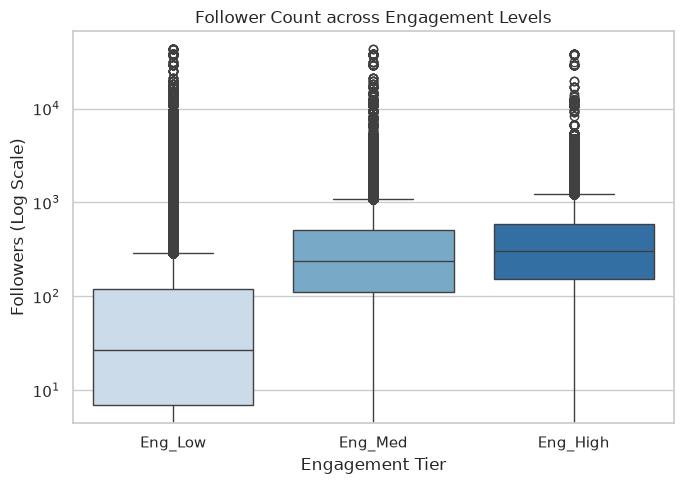

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['TotalEngagement'], bins=30, kde=True, ax=axes[0], color='teal', log_scale=True)
axes[0].set_title("Distribution of Total Engagement (> 0 Likes/Comments)")
axes[0].set_xlabel("Total Engagement (Log Scale)")
axes[0].set_ylabel("Post Count")

sns.boxplot(data=df, x='Engagement_Bin', y='Followers', ax=axes[1], palette='Blues')
axes[1].set_yscale('log')
axes[1].set_title("Follower Count across Engagement Levels")
axes[1].set_xlabel("Engagement Tier")
axes[1].set_ylabel("Followers (Log Scale)")

plt.tight_layout()
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

plt.figure(figsize=(7, 5))
sns.histplot(df["TotalEngagement"], bins=30, kde=True, color="teal", log_scale=True)
plt.title("Distribution of Total Engagement (> 0 Likes/Comments)")
plt.xlabel("Total Engagement (Log Scale)")
plt.ylabel("Post Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Engagement_Bin", y="Followers", palette="Blues")
plt.yscale("log")
plt.title("Follower Count across Engagement Levels")
plt.xlabel("Engagement Tier")
plt.ylabel("Followers (Log Scale)")
plt.tight_layout()
plt.show()

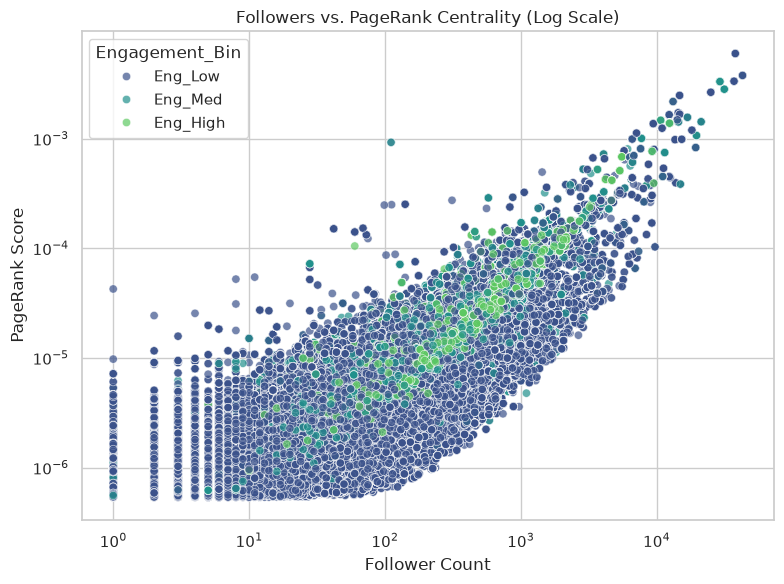

/tmp/ipykernel_4127/1529895519.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/home/hl/uu/informationsutvinning/project/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/hl/uu/informationsutvinning/project/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/hl/uu/informationsutvinning/project/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotl

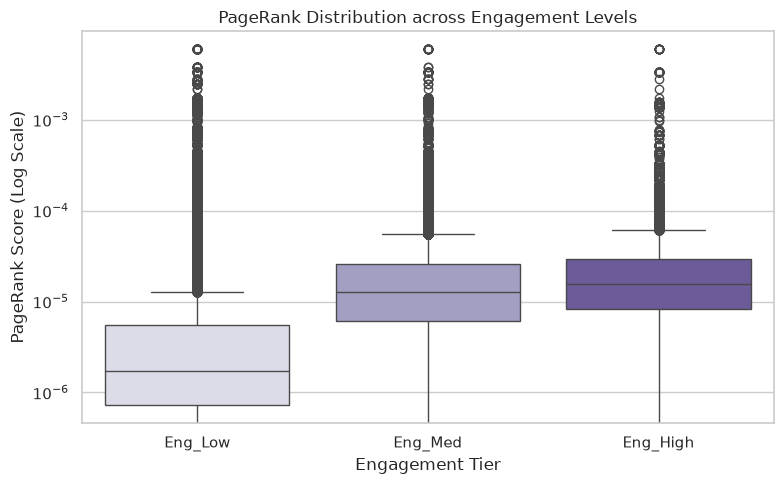

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="Followers",
    y="PageRank",
    hue="Engagement_Bin",
    palette="viridis",
    alpha=0.7,
)
plt.xscale("log")
plt.yscale("log")
plt.title("Followers vs. PageRank Centrality (Log Scale)")
plt.xlabel("Follower Count")
plt.ylabel("PageRank Score")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Engagement_Bin",
    y="PageRank",
    palette="Purples"
)
plt.yscale("log")
plt.title("PageRank Distribution across Engagement Levels")
plt.xlabel("Engagement Tier")
plt.ylabel("PageRank Score (Log Scale)")
plt.tight_layout()
plt.show()

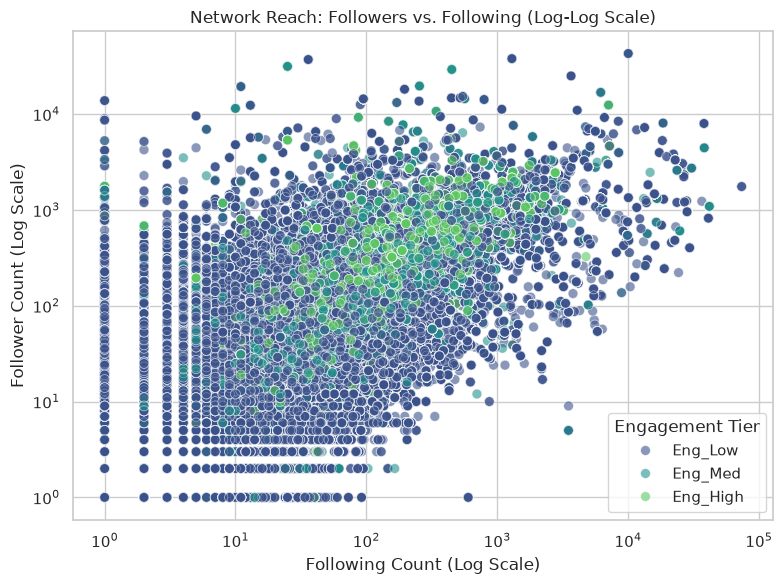

In [84]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df, 
    x='Following', 
    y='Followers', 
    hue='Engagement_Bin', 
    palette='viridis', 
    alpha=0.6, 
    s=50
)

plt.xscale('log')
plt.yscale('log')
plt.title("Network Reach: Followers vs. Following (Log-Log Scale)")
plt.xlabel("Following Count (Log Scale)")
plt.ylabel("Follower Count (Log Scale)")
plt.legend(title="Engagement Tier", loc="lower right")

plt.tight_layout()
plt.show()

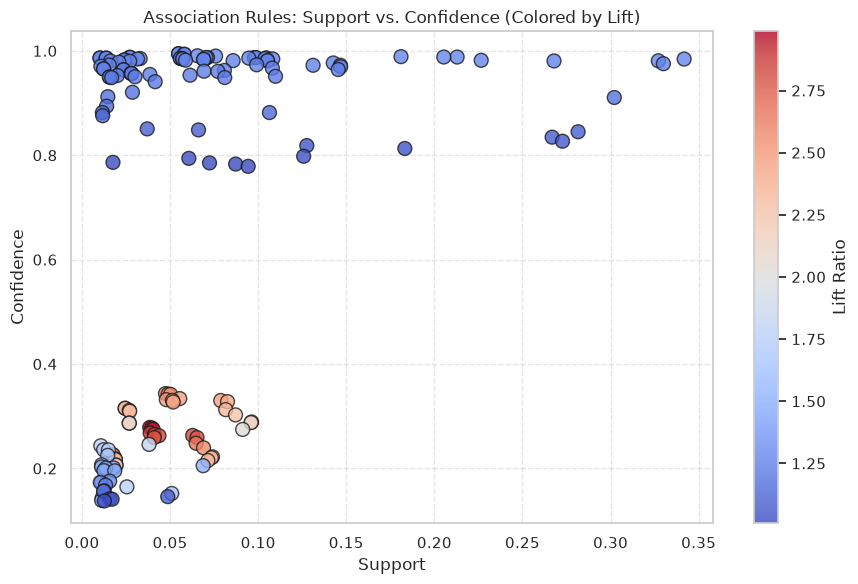

In [85]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    engagement_rules['support'], 
    engagement_rules['confidence'], 
    c=engagement_rules['lift'], 
    cmap='coolwarm', 
    s=100, 
    edgecolors='k', 
    alpha=0.8
)

cbar = plt.colorbar(scatter)
cbar.set_label('Lift Ratio')

plt.title("Association Rules: Support vs. Confidence (Colored by Lift)")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()